In [6]:
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

In [2]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    "Object Detection/caltech-101",
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(224, 224),
    batch_size=16
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    "Object Detection/caltech-101",
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=16
)

class_names = train_ds.class_names

print("Number of Classes:", len(class_names))

Found 9145 files belonging to 102 classes.
Using 7316 files for training.
Found 9145 files belonging to 102 classes.
Using 1829 files for validation.
Number of Classes: 102


In [3]:
base = VGG16(
    weights="Object Detection/vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5",
    include_top=False,
    input_shape=(224, 224, 3)
)

base.trainable = False

In [4]:
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Lambda(preprocess_input),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 102)            │        13,158 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,793,510 (56.43 MB)

 Trainable params: 78,822 (307.90 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [5]:
history = model.fit(
    train_ds.take(100),
    validation_data=test_ds.take(10),
    epochs=3
)

Epoch 1/3


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


100/100 ━━━━━━━━━━━━━━━━━━━━ 209s 2s/step - accuracy: 0.3787 - loss: 3.6569 - val_accuracy: 0.4875 - val_loss: 2.1403
Epoch 2/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 207s 2s/step - accuracy: 0.6925 - loss: 1.2452 - val_accuracy: 0.6313 - val_loss: 1.4690
Epoch 3/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 203s 2s/step - accuracy: 0.8900 - loss: 0.4422 - val_accuracy: 0.7125 - val_loss: 1.1688


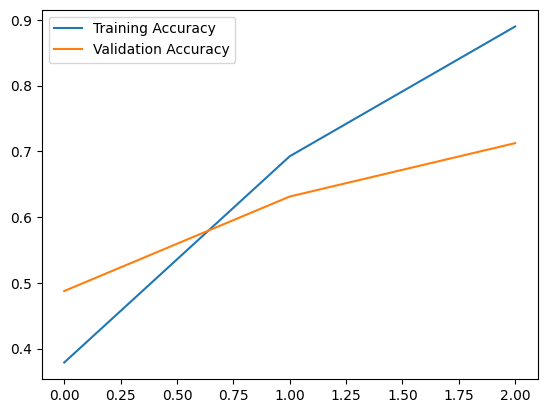

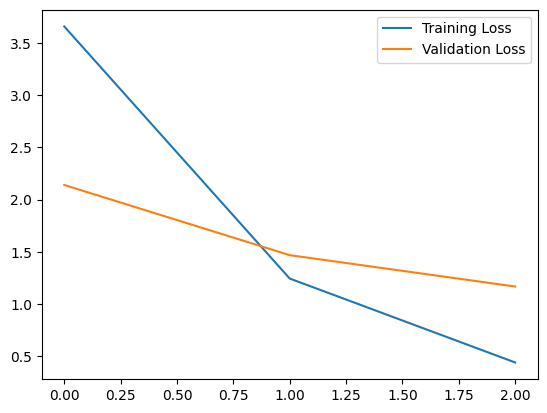

In [7]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.show()

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.show()

In [8]:
loss, accuracy = model.evaluate(test_ds)

print("Loss:", loss)
print("Accuracy:", accuracy)

115/115 ━━━━━━━━━━━━━━━━━━━━ 203s 2s/step - accuracy: 0.7217 - loss: 1.1970
Loss: 1.1969754695892334
Accuracy: 0.7217058539390564


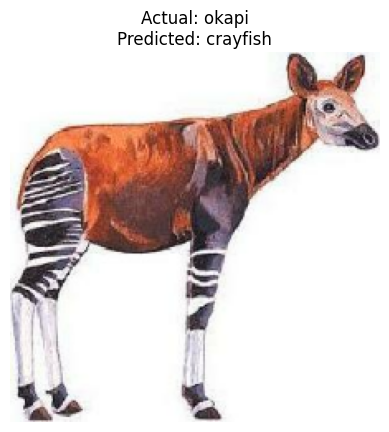

2026-11-02 10:38:54.978193: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [9]:
for images, labels in test_ds.take(1):

    prediction = model.predict(images[:1], verbose=0)
    predicted = prediction.argmax(axis=1)[0]

    plt.imshow(images[0].numpy().astype("uint8"))
    plt.title(f"Actual: {class_names[labels[0]]}\nPredicted: {class_names[predicted]}")
    plt.axis("off")
    plt.show()

In [10]:
# i. Fine tune the top VGG16 layers with a small learning rate.
base.trainable = True
for layer in base.layers[:-6]:
    layer.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(train_ds.take(100), validation_data=test_ds.take(10), epochs=1)


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


100/100 ━━━━━━━━━━━━━━━━━━━━ 292s 3s/step - accuracy: 0.9663 - loss: 0.1498 - val_accuracy: 0.7500 - val_loss: 1.3543


In [11]:
loss, accuracy = model.evaluate(test_ds)

print("Fine Tuned Loss:", loss)
print("Fine Tuned Accuracy:", accuracy)

115/115 ━━━━━━━━━━━━━━━━━━━━ 219s 2s/step - accuracy: 0.7583 - loss: 1.1647
Fine Tuned Loss: 1.1647106409072876
Fine Tuned Accuracy: 0.7583379149436951
